importing libraries and loaded dataset

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlparse

df = pd.read_csv("FakeNewsNet.csv")

df.head()

,title,news_url,source_domain,tweet_num,real
0,Kandi Burruss Explodes Over Rape Accusation on...,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,42,1
1,People's Choice Awards 2018: The best red carp...,https://www.today.com/style/see-people-s-choic...,www.today.com,0,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,63,1
3,Colombian singer Maluma sparks rumours of inap...,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,20,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,38,1


extract  external links

In [3]:
def extract_urls(text):
    if pd.isna(text):
        return []
    
    return re.findall(r'https?://\S+', str(text))

df['external_links'] = df['news_url'].apply(extract_urls)

df['link_count'] = df['external_links'].apply(len)

display(df[['title', 'external_links', 'link_count']].head())

,title,external_links,link_count
0,Kandi Burruss Explodes Over Rape Accusation on...,[http://toofab.com/2017/05/08/real-housewives-...,1
1,People's Choice Awards 2018: The best red carp...,[https://www.today.com/style/see-people-s-choi...,1
2,Sophia Bush Sends Sweet Birthday Message to 'O...,[https://www.etonline.com/news/220806_sophia_b...,1
3,Colombian singer Maluma sparks rumours of inap...,[https://www.dailymail.co.uk/news/article-3365...,1
4,Gossip Girl 10 Years Later: How Upper East Sid...,[https://www.zerchoo.com/entertainment/gossip-...,1


extract domains

In [4]:
def extract_domain(url):
    if pd.isna(url):
        return None
    
    return urlparse(str(url)).netloc.lower().replace('www.', '')

df['extracted_domain'] = df['news_url'].apply(extract_domain)

display(df[['news_url', 'source_domain', 'extracted_domain']].head())

,news_url,source_domain,extracted_domain
0,http://toofab.com/2017/05/08/real-housewives-a...,toofab.com,toofab.com
1,https://www.today.com/style/see-people-s-choic...,www.today.com,today.com
2,https://www.etonline.com/news/220806_sophia_bu...,www.etonline.com,etonline.com
3,https://www.dailymail.co.uk/news/article-33655...,www.dailymail.co.uk,dailymail.co.uk
4,https://www.zerchoo.com/entertainment/gossip-g...,www.zerchoo.com,zerchoo.com


identify frequently linked domains

In [5]:
domain_frequency = df['extracted_domain'].value_counts()

print("Frequently Linked Domains:")
print(domain_frequency.head(10))

Frequently Linked Domains:
extracted_domain
                         5147
people.com               1570
dailymail.co.uk           770
en.wikipedia.org          618
etonline.com              585
usmagazine.com            562
longroom.com              562
usatoday.com              301
hollywoodreporter.com     299
variety.com               259
Name: count, dtype: int64


comapare domains in real n fake news

In [6]:
df['label'] = df['real'].map({
    1: 'Real',
    0: 'Fake'
})

domain_analysis = pd.crosstab(
    df['extracted_domain'],
    df['label']
)

display(domain_analysis)

label,Fake,Real
extracted_domain,,
,5147,0
1001.com.do,0,1
100percentfedup.com,1,0
101kgb.iheart.com,0,1
1029now.iheart.com,0,1
...,...,...
zerohedge.com,1,0
zig.com,0,11
zimbabwe-today.com,1,0


Analyse Tweet Counts

In [7]:
tweet_analysis = df.groupby('label')['tweet_num'].agg(
    ['mean', 'sum', 'max']
)

display(tweet_analysis)

,mean,sum,max
label,,,
Fake,132.693484,763651,29060
Real,74.525027,1299791,27377


 identify domains associated with Fake News

fake_domains = df[df['real'] == 0]['extracted_domain'].value_counts()

print("Domains appearing in Fake News:")
print(fake_domains)

Visualisation

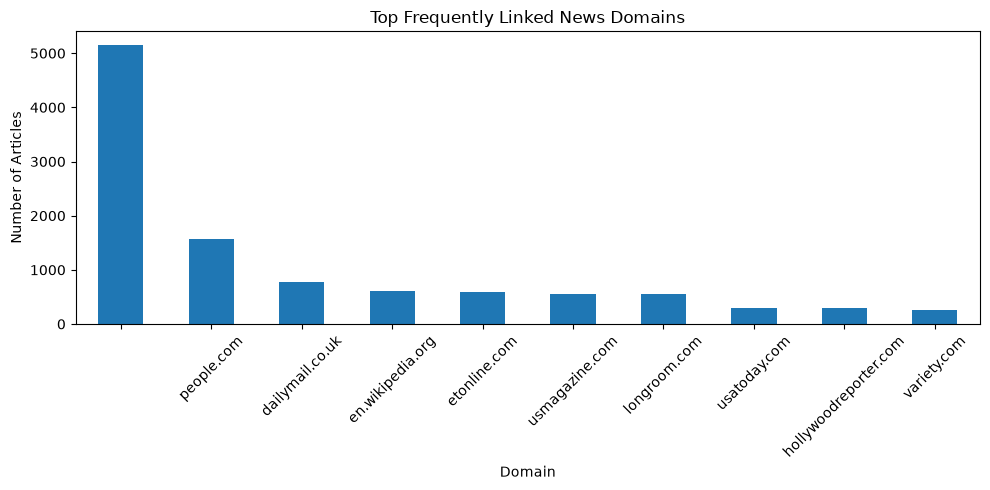

In [8]:
plt.figure(figsize=(10, 5))

domain_frequency.head(10).plot(kind='bar')

plt.title("Top Frequently Linked News Domains")
plt.xlabel("Domain")
plt.ylabel("Number of Articles")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Fake vs Real News Comparison

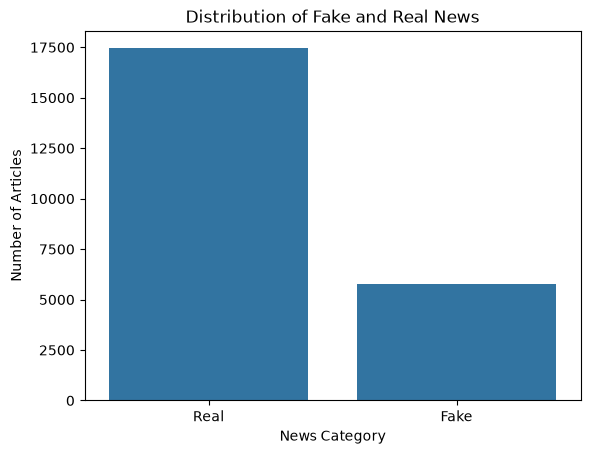

In [9]:
sns.countplot(data=df, x='label')

plt.title("Distribution of Fake and Real News")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")

plt.show()

Final Results

In [10]:
print("EXTERNAL LINK AND MISINFORMATION ANALYSIS")

print("\nTotal Articles:", len(df))

print("Total External Links:", df['link_count'].sum())

print("\nUnique Domains:", df['extracted_domain'].nunique())

print("\nTop 10 Domains:")
print(domain_frequency.head(10))

print("\nFake vs Real Domain Analysis:")
display(domain_analysis)

print("\nTweet Engagement Analysis:")
display(tweet_analysis)

EXTERNAL LINK AND MISINFORMATION ANALYSIS

Total Articles: 23196
Total External Links: 17719

Unique Domains: 2070

Top 10 Domains:
extracted_domain
                         5147
people.com               1570
dailymail.co.uk           770
en.wikipedia.org          618
etonline.com              585
usmagazine.com            562
longroom.com              562
usatoday.com              301
hollywoodreporter.com     299
variety.com               259
Name: count, dtype: int64

Fake vs Real Domain Analysis:


label,Fake,Real
extracted_domain,,
,5147,0
1001.com.do,0,1
100percentfedup.com,1,0
101kgb.iheart.com,0,1
1029now.iheart.com,0,1
...,...,...
zerohedge.com,1,0
zig.com,0,11
zimbabwe-today.com,1,0



Tweet Engagement Analysis:


,mean,sum,max
label,,,
Fake,132.693484,763651,29060
Real,74.525027,1299791,27377
